# 4. lecke – ki marad 60 pont alatt matekból?

**Cél:** a `StudentsPerformance.csv` adataiból egy osztályozó építése, amely **0 vagy 1** értéket jósol. A pozitív osztály (1) az, akinek a **matematika pontszáma 60 alatt van** („kockázatos”); a 0 az, aki 60 vagy afölött teljesített. A jegyzetfüzet minden adatból tanuló lépést kizárólag a tanító részen illeszt, és a tesztrészt csak a végén, egyszer használja.

## 1. A kérdés, a tippünk és a szereplők

**Kérdés:** a diák *háttere* alapján (a vizsga előtt ismert adatok) mennyire jósolható meg, hogy matekból 60 pont alatt marad?

**Hipotézis (H1):** azok a diákok, akik **kedvezményes/ingyenes ebédet** kapnak (`lunch = free/reduced`) és **nem végeztek felkészítő kurzust** (`prep_course = none`), nagyobb eséllyel maradnak 60 pont alatt matekból. Ha igaz, akkor már ez a két változó egyedül is **jobban jósol, mint a véletlen** (a dummy alapmodell), a többi háttérváltozó pedig legfeljebb finomít rajta.

| Szerep | Változó | Jelentés |
|---|---|---|
| **Célváltozó** | `at_risk` | 1, ha `math < 60`, különben 0 |
| **Fő hipotézis-változó** | `lunch` | `standard` vagy `free/reduced` ebéd (a család anyagi helyzetének közelítése) |
| **Fő hipotézis-változó** | `prep_course` | `completed` vagy `none` felkészítő kurzus |
| Háttérváltozó | `gender`, `group`, `parent_edu` | nem, anonimizált csoport (A–E), a szülő legmagasabb iskolai végzettsége |
| **Kizárt** | `reading`, `writing` | az olvasás- és íráspontszám a matekpontszámmal együtt mérődik; benne hagyva a kérdés triviális lenne, és a „vizsga előtt ismert háttér” nem állna |

**Feltételezés a hibák költségéről:** egy kihagyott kockázatos diák (modell: 0, valóság: 1) súlyosabb, mert elmarad a korai segítség; egy fölösleges riasztás (modell: 1, valóság: 0) csak plusz figyelem. Ezek feltevések, nem mért költségek.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#7b9acc", "#e07a5f", "#8d99ae"

for candidate in [Path("StudentsPerformance.csv"), Path("lesson 4") / "StudentsPerformance.csv",
                  Path("/mnt/user-data/uploads/StudentsPerformance.csv")]:
    if candidate.is_file():
        data_path = candidate
        break
else:
    raise FileNotFoundError("Nem található a StudentsPerformance.csv.")

RENAME = {"gender": "gender", "race/ethnicity": "group", "parental level of education": "parent_edu",
          "lunch": "lunch", "test preparation course": "prep_course",
          "math score": "math", "reading score": "reading", "writing score": "writing"}
raw = pd.read_csv(data_path)
if set(raw.columns) != set(RENAME):
    raise ValueError(f"A tényleges oszlopok eltérnek a vártaktól: {raw.columns.tolist()}")
df = raw.rename(columns=RENAME)

MATH_CUTOFF = 60
FEATURES = ["gender", "group", "parent_edu", "lunch", "prep_course"]   # reading/writing szándékosan kimarad
y = (df["math"] < MATH_CUTOFF).astype("int8")                          # 1 = kockázatos
X = df[FEATURES].copy()

print(f"A tábla mérete: {df.shape[0]} sor × {df.shape[1]} oszlop.")
print(f"Célváltozó: at_risk = 1, ha math < {MATH_CUTOFF}.")
print(f"Pozitív (1) osztály: {int(y.sum())}/{len(y)} sor = {y.mean():.2%}; a „mindenki rendben” modell pontossága {1 - y.mean():.2%}.")
print("Felhasznált jellemzők:", FEATURES)

A tábla mérete: 1000 sor × 8 oszlop.
Célváltozó: at_risk = 1, ha math < 60.
Pozitív (1) osztály: 323/1000 sor = 32.30%; a „mindenki rendben” modell pontossága 67.70%.
Felhasznált jellemzők: ['gender', 'group', 'parent_edu', 'lunch', 'prep_course']


## 2. Először nézzük meg az adatot

Az ábrák **leíró** jellegűek: megmutatják, hol van a küszöb, és a hipotézis változói mentén hogyan oszlik meg a kockázat. Nem modellválasztási eszközök.

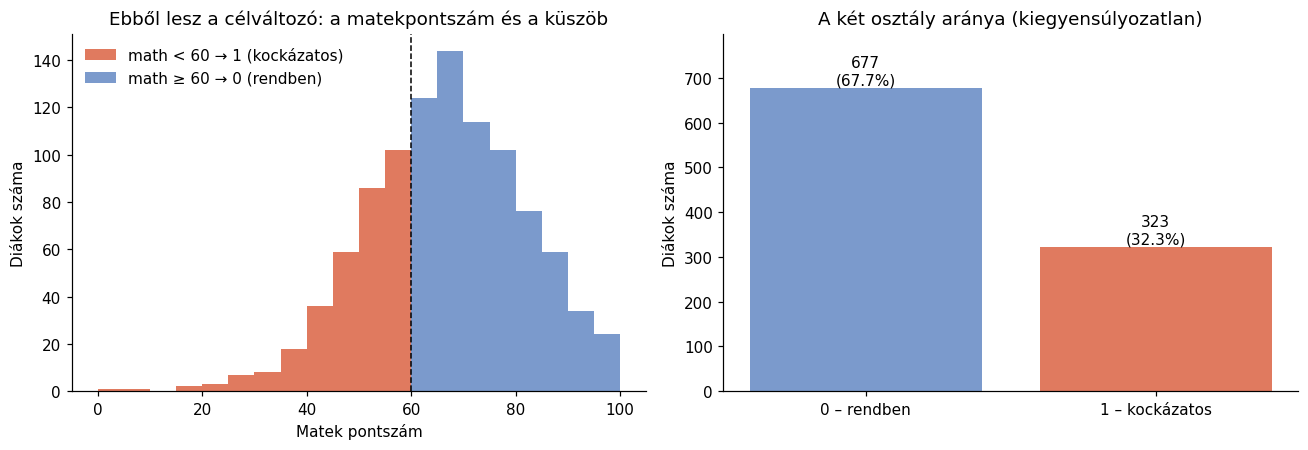

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.arange(0, 105, 5)
axes[0].hist(df.loc[df["math"] < MATH_CUTOFF, "math"], bins=bins, color=ORANGE, label=f"math < {MATH_CUTOFF} → 1 (kockázatos)")
axes[0].hist(df.loc[df["math"] >= MATH_CUTOFF, "math"], bins=bins, color=BLUE, label=f"math ≥ {MATH_CUTOFF} → 0 (rendben)")
axes[0].axvline(MATH_CUTOFF, color="black", ls="--", lw=1)
axes[0].set_title("Ebből lesz a célváltozó: a matekpontszám és a küszöb")
axes[0].set_xlabel("Matek pontszám"); axes[0].set_ylabel("Diákok száma"); axes[0].legend(frameon=False)

counts = y.value_counts().reindex([0, 1])
bars = axes[1].bar(["0 – rendben", "1 – kockázatos"], counts.values, color=[BLUE, ORANGE])
for bar, value in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 8, f"{value}\n({value / len(y):.1%})", ha="center")
axes[1].set_ylim(0, counts.max() * 1.18)
axes[1].set_title("A két osztály aránya (kiegyensúlyozatlan)"); axes[1].set_ylabel("Diákok száma")
fig.tight_layout(); plt.show()

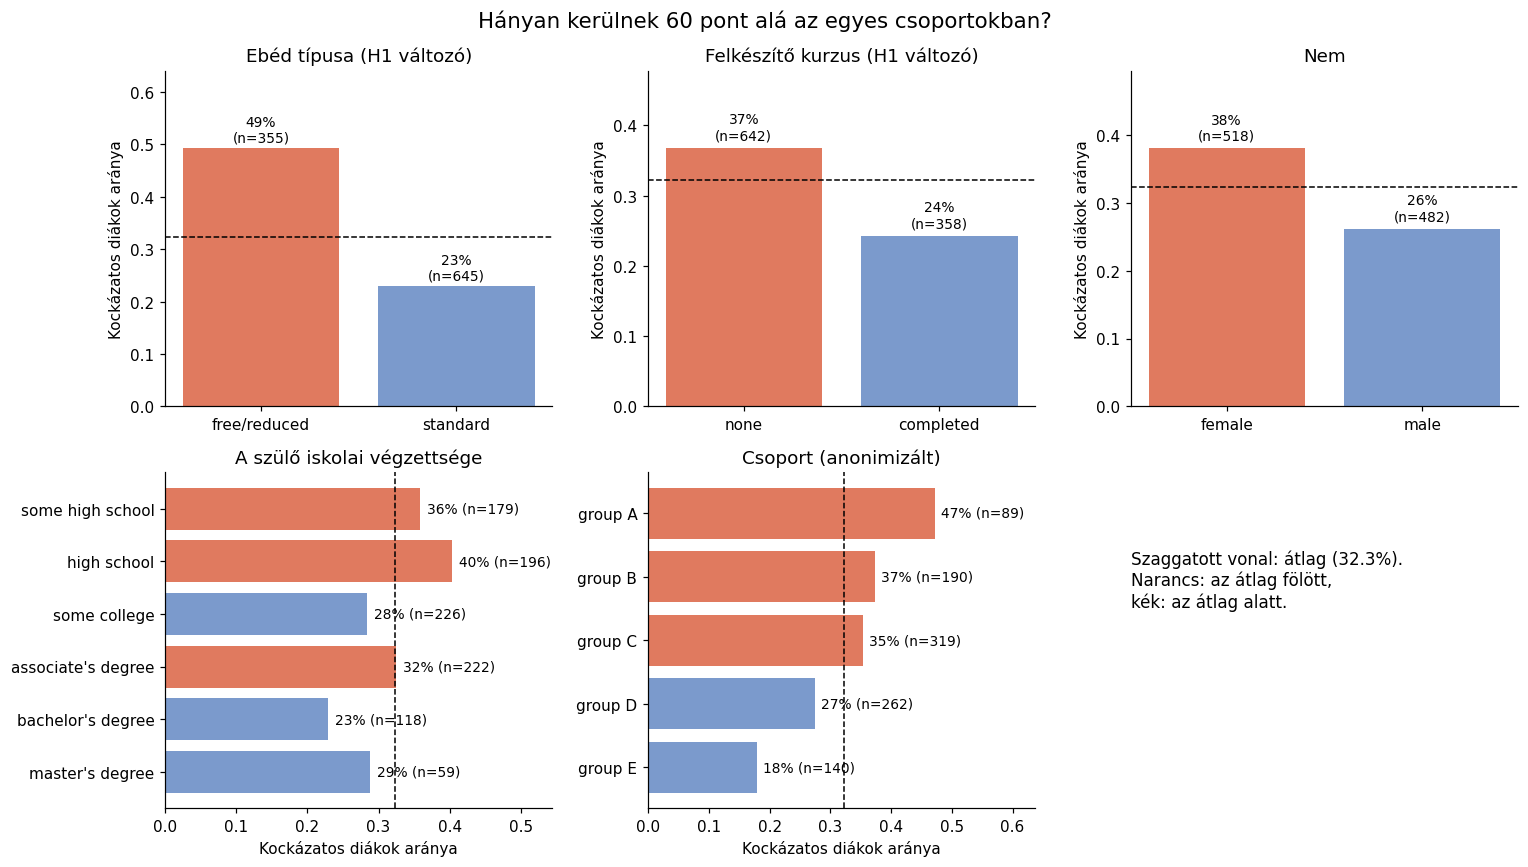

In [3]:
overall = y.mean()
EDU_ORDER = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]

def rate_bars(ax, col, order=None, horizontal=False, title=None):
    grouped = y.groupby(df[col])
    rate, n = grouped.mean(), grouped.size()
    order = order or rate.sort_values(ascending=False).index.tolist()
    rate, n = rate.reindex(order), n.reindex(order)
    colors = [ORANGE if r > overall else BLUE for r in rate]
    if horizontal:
        ax.barh(order, rate.values, color=colors); ax.invert_yaxis()
        ax.axvline(overall, color="black", ls="--", lw=1)
        for i, (r, k) in enumerate(zip(rate.values, n.values)):
            ax.text(r + 0.01, i, f"{r:.0%} (n={k})", va="center", fontsize=9)
        ax.set_xlim(0, rate.max() * 1.35); ax.set_xlabel("Kockázatos diákok aránya")
    else:
        ax.bar(order, rate.values, color=colors)
        ax.axhline(overall, color="black", ls="--", lw=1)
        for i, (r, k) in enumerate(zip(rate.values, n.values)):
            ax.text(i, r + 0.012, f"{r:.0%}\n(n={k})", ha="center", fontsize=9)
        ax.set_ylim(0, rate.max() * 1.3); ax.set_ylabel("Kockázatos diákok aránya")
    ax.set_title(title or col)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
rate_bars(axes[0, 0], "lunch", title="Ebéd típusa (H1 változó)")
rate_bars(axes[0, 1], "prep_course", title="Felkészítő kurzus (H1 változó)")
rate_bars(axes[0, 2], "gender", title="Nem")
rate_bars(axes[1, 0], "parent_edu", order=EDU_ORDER, horizontal=True, title="A szülő iskolai végzettsége")
rate_bars(axes[1, 1], "group", order=sorted(df["group"].unique()), horizontal=True, title="Csoport (anonimizált)")
axes[1, 2].axis("off")
axes[1, 2].text(0, 0.6, f"Szaggatott vonal: átlag ({overall:.1%}).\nNarancs: az átlag fölött,\nkék: az átlag alatt.", fontsize=11)
fig.suptitle("Hányan kerülnek 60 pont alá az egyes csoportokban?", fontsize=14)
fig.tight_layout(); plt.show()

A legkockázatosabb csoport (kedvezményes ebéd, nincs kurzus): 54.0% – a legkevésbé kockázatos (normál ebéd, van kurzus): 14.5%.


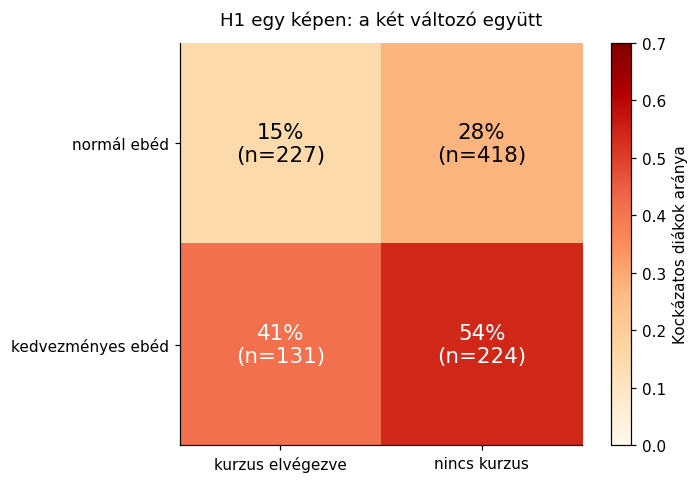

In [4]:
combo_rate = y.groupby([df["lunch"], df["prep_course"]]).mean().unstack()
combo_n = y.groupby([df["lunch"], df["prep_course"]]).size().unstack()
combo_rate = combo_rate.loc[["standard", "free/reduced"], ["completed", "none"]]
combo_n = combo_n.loc[["standard", "free/reduced"], ["completed", "none"]]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(combo_rate.values, cmap="OrRd", vmin=0, vmax=0.7)
ax.set_xticks([0, 1], ["kurzus elvégezve", "nincs kurzus"]); ax.set_yticks([0, 1], ["normál ebéd", "kedvezményes ebéd"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{combo_rate.values[i, j]:.0%}\n(n={combo_n.values[i, j]})", ha="center", va="center", fontsize=14,
                color="white" if combo_rate.values[i, j] > 0.4 else "black")
ax.set_title("H1 egy képen: a két változó együtt", pad=12)
fig.colorbar(im, ax=ax, label="Kockázatos diákok aránya"); fig.tight_layout(); plt.show()
print("A legkockázatosabb csoport (kedvezményes ebéd, nincs kurzus):", f"{combo_rate.loc['free/reduced', 'none']:.1%}",
      "– a legkevésbé kockázatos (normál ebéd, van kurzus):", f"{combo_rate.loc['standard', 'completed']:.1%}.")

## 3. Rendben van az adat?

A hiányzó értékeket, a duplikált sorokat és a kategóriaértékeket külön ellenőrizzük. Nem törlünk és nem töltünk ki semmit automatikusan: ha a számláló nem nulla, a notebook megáll, mert akkor indokolt tisztítási döntés kell. Az imputálás a későbbi pipeline-ban szerepel, tanító adatokon illesztve.

In [5]:
missing = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())
score_range_ok = bool(df[["math", "reading", "writing"]].apply(lambda s: s.between(0, 100).all()).all())
print(f"Hiányzó cellák: {missing}; teljesen duplikált sorok: {duplicates}; pontszámok a 0–100 tartományban: {score_range_ok}.")
for col in FEATURES:
    print(f"  {col}: {df[col].nunique()} érték – {sorted(df[col].unique())}")
if missing or duplicates or not score_range_ok:
    raise ValueError("Az ellenőrzés hibát talált; indokolt tisztítási döntés szükséges.")
print("Döntés: nincs hiány, duplikátum vagy érvénytelen pontszám, ezért egyetlen sort vagy mezőt sem módosítunk.")

Hiányzó cellák: 0; teljesen duplikált sorok: 0; pontszámok a 0–100 tartományban: True.
  gender: 2 érték – ['female', 'male']
  group: 5 érték – ['group A', 'group B', 'group C', 'group D', 'group E']
  parent_edu: 6 érték – ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']
  lunch: 2 érték – ['free/reduced', 'standard']
  prep_course: 2 érték – ['completed', 'none']
Döntés: nincs hiány, duplikátum vagy érvénytelen pontszám, ezért egyetlen sort vagy mezőt sem módosítunk.


## 4. A teszthalmaz zárolása

A 1 000 sorból 20%-ot végső tesztre tartunk fenn, rétegzéssel őrizzük a címkearányt, a 42-es véletlenmag a reprodukálhatóságért van. E pont előtt semmit nem illesztettünk; a tesztcímkéket a 10. fejezetig nem használjuk.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Tanító rész: {len(X_train)} sor; tesztrész: {len(X_test)} sor.")
print(f"Pozitív arány: tanító {y_train.mean():.2%} ({int(y_train.sum())}/{len(y_train)}), teszt {y_test.mean():.2%} ({int(y_test.sum())}/{len(y_test)}).")

Tanító rész: 800 sor; tesztrész: 200 sor.
Pozitív arány: tanító 32.25% (258/800), teszt 32.50% (65/200).


## 5. Az adat modellbarátra alakítása

Minden jellemző kategorikus, ezért a pipeline módusszal imputál (most nincs mit), majd **one-hot kódol**: ez nem rendel mesterséges sorrendet a kategóriákhoz. Az ismeretlen kategóriát az `handle_unknown="ignore"` kezeli. Mindez a pipeline-ban él, így a keresztvalidáció minden hajtásán csak a tanító rész alapján illeszkedik (nincs szivárgás).

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

def make_pipeline(family, columns):
    columns = list(columns)
    prep = ColumnTransformer([("kategorikus", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), columns)])
    models = {
        "dummy": DummyClassifier(strategy="prior"),
        "logistic": LogisticRegression(max_iter=3000, random_state=42),
        "decision_tree": DecisionTreeClassifier(random_state=42),
        "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=1),
        "hist_gb": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=42),
    }
    if family not in models:
        raise ValueError(f"Ismeretlen modellcsalád: {family}")
    return Pipeline([("elofeldolgozas", prep), ("modell", models[family])])

print("Pipeline-ok elérhetők:", ["dummy", "logistic", "decision_tree", "random_forest", "hist_gb"])

Pipeline-ok elérhetők: ['dummy', 'logistic', 'decision_tree', 'random_forest', 'hist_gb']


## 6. Mivel mérünk? Előre eldöntött mércék

A fő összehasonlítás a **PR-AUC** (átlagos precizitás) és a **kiegyensúlyozott pontosság** (a két osztály recallja átlaga). A nyers pontosság félrevezető, mert a „mindenki rendben” modell is 67–68%-ot ér el. A végső értékeléshez zavarossági mátrixot és a legkockázatosabb 20% találati arányát is közöljük. Az összes modell **ugyanazokon** az 5 hajtásos, 2 ismétléses rétegzett felosztásokon kerül mérésre; a szórás a 10 hajtáspontszám mintaszórása.

In [8]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict, cross_validate

SCORING = {"kiegyensulyozott_pontossag": "balanced_accuracy", "atlagos_precizitas": "average_precision"}
CV_N_SPLITS, CV_N_REPEATS = 5, 2
CV = RepeatedStratifiedKFold(n_splits=CV_N_SPLITS, n_repeats=CV_N_REPEATS, random_state=42)
print("Mérőszámok:", ", ".join(SCORING), "| közös CV: 5 hajtás × 2 ismétlés, random_state=42 (10 pontszám modellenként).")

Mérőszámok: kiegyensulyozott_pontossag, atlagos_precizitas | közös CV: 5 hajtás × 2 ismétlés, random_state=42 (10 pontszám modellenként).


## 7. Versenyfutás: melyik modell a legjobb?

Dummy → logisztikus regresszió → döntési fa → Random Forest → gradient boosting, azonos felosztásokon, mind az 5 háttérváltozóval. A választás szabálya előre rögzített: nyer a legnagyobb átlagos PR-AUC, **de** ha egy bonyolultabb modell előnye a logisztikus regresszióhoz képest nem nagyobb a páros különbség szórásánál, az egyszerűbbet (logisztikus) tartjuk meg.

A modell-létra alapján kiválasztott család: logistic.


,modell,kiegyensúlyozott pontosság (átlag ± szórás),PR-AUC (átlag ± szórás)
0,dummy,0.500 ± 0.000,0.323 ± 0.003
1,logistic,0.587 ± 0.033,0.541 ± 0.059
2,decision_tree,0.541 ± 0.032,0.398 ± 0.039
3,random_forest,0.576 ± 0.041,0.513 ± 0.062
4,hist_gb,0.593 ± 0.030,0.510 ± 0.060


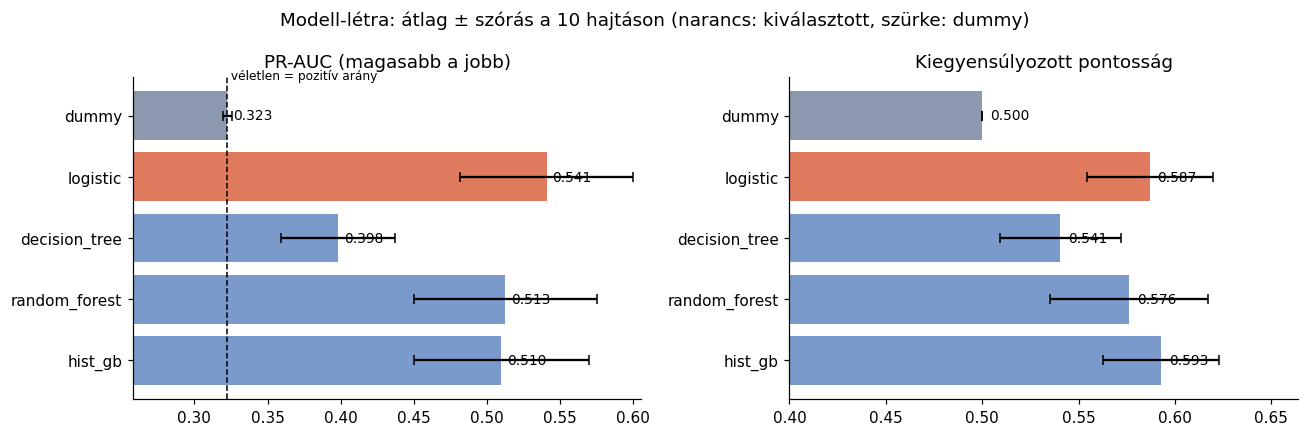

In [9]:
MODEL_NAMES = ["dummy", "logistic", "decision_tree", "random_forest", "hist_gb"]
ladder, rows = {}, []
for family in MODEL_NAMES:
    scores = cross_validate(make_pipeline(family, FEATURES), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1, error_score="raise")
    ladder[family] = scores
    ba, ap = scores["test_kiegyensulyozott_pontossag"], scores["test_atlagos_precizitas"]
    rows.append({"modell": family,
                 "kiegyensúlyozott pontosság (átlag ± szórás)": f"{ba.mean():.3f} ± {ba.std(ddof=1):.3f}",
                 "PR-AUC (átlag ± szórás)": f"{ap.mean():.3f} ± {ap.std(ddof=1):.3f}"})
display(pd.DataFrame(rows))

SIMPLE_TO_COMPLEX = ["logistic", "decision_tree", "random_forest", "hist_gb"]
best_family = max(SIMPLE_TO_COMPLEX, key=lambda f: ladder[f]["test_atlagos_precizitas"].mean())
if best_family != "logistic":
    gain = ladder[best_family]["test_atlagos_precizitas"] - ladder["logistic"]["test_atlagos_precizitas"]
    if gain.mean() <= gain.std(ddof=1):
        print(f"{best_family} előnye a logisztikushoz képest: {gain.mean():+.4f} ± {gain.std(ddof=1):.4f}, azaz a zajon belül → az egyszerűbbet tartjuk.")
        best_family = "logistic"
print(f"A modell-létra alapján kiválasztott család: {best_family}.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in [(axes[0], "test_atlagos_precizitas", "PR-AUC (magasabb a jobb)"),
                       (axes[1], "test_kiegyensulyozott_pontossag", "Kiegyensúlyozott pontosság")]:
    means = [ladder[f][key].mean() for f in MODEL_NAMES]; stds = [ladder[f][key].std(ddof=1) for f in MODEL_NAMES]
    colors = [ORANGE if f == best_family else (GREY if f == "dummy" else BLUE) for f in MODEL_NAMES]
    ax.barh(MODEL_NAMES, means, xerr=stds, color=colors, capsize=3); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlim(min(means) * 0.8, max(means) * 1.12)
    for i, m in enumerate(means):
        ax.text(m + 0.004, i, f"{m:.3f}", va="center", fontsize=9)
axes[0].axvline(y_train.mean(), color="black", ls="--", lw=1)
axes[0].text(y_train.mean(), -0.55, " véletlen = pozitív arány", fontsize=8, va="bottom")
fig.suptitle("Modell-létra: átlag ± szórás a 10 hajtáson (narancs: kiválasztott, szürke: dummy)")
fig.tight_layout(); plt.show()

## 8. Beigazolódik a tippünk?

**Előre rögzített szabály:** a H1 akkor támogatott, ha a csak `lunch` + `prep_course` változókat használó logisztikus regresszió PR-AUC-ja a dummyhoz képest **páros átlagos különbségben nagyobb, mint a különbség hajtásszórása**. Ezután ugyanígy megnézzük, hoz-e többet a másik három háttérváltozó (`gender`, `group`, `parent_edu`). Ugyanazokat a foldokat használjuk, ezért a különbség páros.

H1: ebéd + kurzus − dummy: +0.1286 ± 0.0394; nagyobb a hajtásszórásnál → valós különbség.
a másik 3 változó hozzáadása: +0.0896 ± 0.0345; nagyobb a hajtásszórásnál → valós különbség.


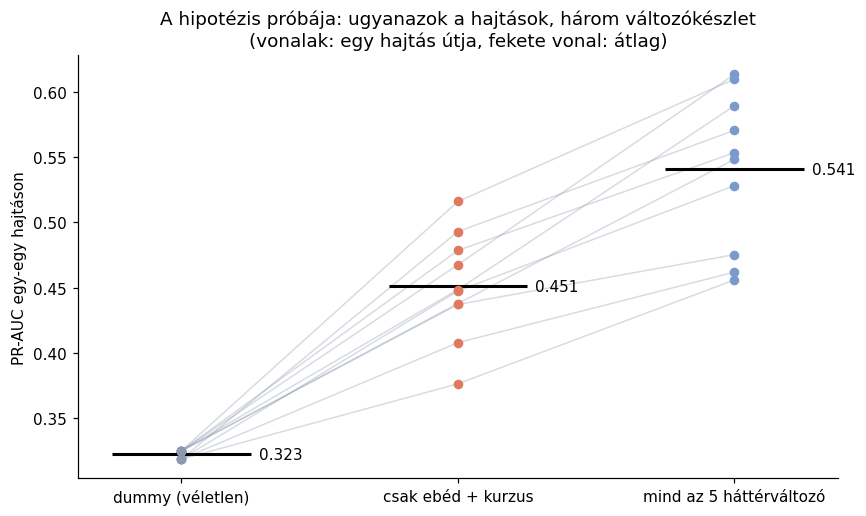

In [10]:
H_FEATURES = ["lunch", "prep_course"]
sets = {"dummy (véletlen)": None, "csak ebéd + kurzus": H_FEATURES, "mind az 5 háttérváltozó": FEATURES}
fold_scores = {}
for name, cols in sets.items():
    if cols is None:
        fold_scores[name] = ladder["dummy"]["test_atlagos_precizitas"]
    else:
        fold_scores[name] = cross_validate(make_pipeline("logistic", cols), X_train[cols], y_train, cv=CV,
                                           scoring="average_precision", n_jobs=1, error_score="raise")["test_score"]
names = list(sets)
d_h1 = fold_scores[names[1]] - fold_scores[names[0]]
d_more = fold_scores[names[2]] - fold_scores[names[1]]
for label, d in [("H1: ebéd + kurzus − dummy", d_h1), ("a másik 3 változó hozzáadása", d_more)]:
    verdict = "nagyobb a hajtásszórásnál → valós különbség" if d.mean() > d.std(ddof=1) else "nem nagyobb a hajtásszórásnál → nem állítjuk, hogy segít"
    print(f"{label}: {d.mean():+.4f} ± {d.std(ddof=1):.4f}; {verdict}.")

fig, ax = plt.subplots(figsize=(8, 4.8))
xs = np.arange(len(names))
for k in range(len(fold_scores[names[0]])):
    ax.plot(xs, [fold_scores[n][k] for n in names], color=GREY, alpha=0.35, lw=1)
for i, n in enumerate(names):
    ax.scatter(np.full(len(fold_scores[n]), i), fold_scores[n], color=[GREY, ORANGE, BLUE][i], s=28, zorder=3)
    ax.hlines(fold_scores[n].mean(), i - 0.25, i + 0.25, color="black", lw=2)
    ax.text(i + 0.28, fold_scores[n].mean(), f"{fold_scores[n].mean():.3f}", va="center")
ax.set_xticks(xs, names); ax.set_ylabel("PR-AUC egy-egy hajtáson")
ax.set_title("A hipotézis próbája: ugyanazok a hajtások, három változókészlet\n(vonalak: egy hajtás útja, fekete vonal: átlag)")
fig.tight_layout(); plt.show()

Figyelem: ez leíró ábra egyetlen modellről, nem ok-okozati állítás; a referenciakategória a felirat végén áll.


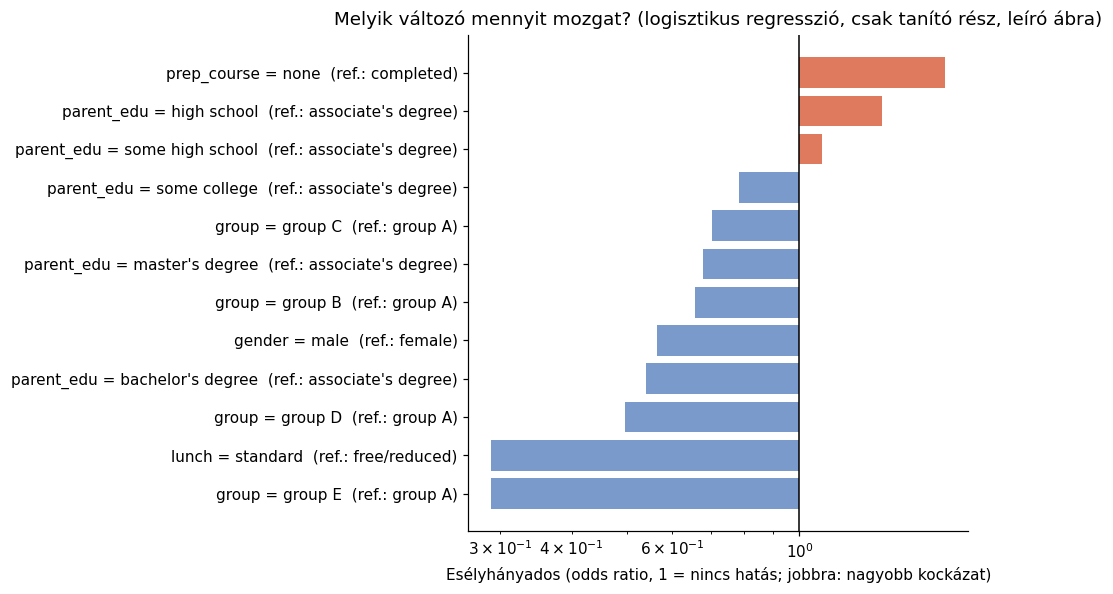

In [11]:
Xd = pd.get_dummies(X_train, drop_first=True).astype(float)
reference = {c: sorted(X_train[c].unique())[0] for c in FEATURES}
lr = LogisticRegression(max_iter=3000).fit(Xd, y_train)
odds = pd.Series(np.exp(lr.coef_[0]), index=Xd.columns).sort_values()
labels = []
for name in odds.index:
    col = next(c for c in FEATURES if name.startswith(c + "_"))
    labels.append(f"{col} = {name[len(col) + 1:]}  (ref.: {reference[col]})")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, odds.values - 1, left=1, color=[ORANGE if v > 1 else BLUE for v in odds.values])
ax.axvline(1, color="black", lw=1); ax.set_xscale("log")
ax.set_xlabel("Esélyhányados (odds ratio, 1 = nincs hatás; jobbra: nagyobb kockázat)")
ax.set_title("Melyik változó mennyit mozgat? (logisztikus regresszió, csak tanító rész, leíró ábra)")
fig.tight_layout(); plt.show()
print("Figyelem: ez leíró ábra egyetlen modellről, nem ok-okozati állítás; a referenciakategória a felirat végén áll.")

## 9. Érdemes tovább csavargatni a gombokat?

Véletlen kereséssel (8 jelölt, 3 hajtás, PR-AUC) hangoljuk a kiválasztott modellcsaládot. Ezután a hangolt és az alap változat **új, a keresés által nem látott** felosztásokon (`random_state=2026`) kap páros összehasonlítást. Ha a hangolt változat előnye nem nagyobb a különbség szórásánál, az egyszerűbb alapváltozatot tartjuk meg.

In [12]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

spaces = {
    "logistic": {"modell__C": loguniform(0.01, 100), "modell__class_weight": [None, "balanced"]},
    "decision_tree": {"modell__max_depth": [2, 3, 4, 5, 6, 8], "modell__min_samples_leaf": randint(1, 30)},
    "random_forest": {"modell__n_estimators": randint(100, 400), "modell__max_depth": [None, 3, 5, 8],
                      "modell__min_samples_leaf": randint(1, 15), "modell__max_features": ["sqrt", 0.7, 1.0]},
    "hist_gb": {"modell__max_depth": [2, 3, 4], "modell__learning_rate": loguniform(0.02, 0.2),
                "modell__max_iter": randint(60, 250), "modell__min_samples_leaf": randint(10, 60)},
}
base_candidate = make_pipeline(best_family, FEATURES)
search = RandomizedSearchCV(base_candidate, spaces[best_family], n_iter=8, scoring="average_precision", cv=3,
                            random_state=42, n_jobs=1, refit=True, error_score="raise")
search.fit(X_train, y_train)
print(f"Hangolt család: {best_family}; legjobb 3 hajtásos keresési PR-AUC: {search.best_score_:.4f}.")
print("Legjobb paraméterek:", search.best_params_)

fresh_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2026)
base_fresh = cross_validate(base_candidate, X_train, y_train, cv=fresh_cv, scoring="average_precision", n_jobs=1)["test_score"]
tuned_fresh = cross_validate(search.best_estimator_, X_train, y_train, cv=fresh_cv, scoring="average_precision", n_jobs=1)["test_score"]
tuning_delta = tuned_fresh - base_fresh
print(f"Új felosztásokon: alap {base_fresh.mean():.4f} ± {base_fresh.std(ddof=1):.4f}; hangolt {tuned_fresh.mean():.4f} ± {tuned_fresh.std(ddof=1):.4f}.")
print(f"Páros különbség (hangolt − alap): {tuning_delta.mean():+.4f} ± {tuning_delta.std(ddof=1):.4f}.")
keep_tuned = bool(tuning_delta.mean() > tuning_delta.std(ddof=1))
final_estimator = search.best_estimator_ if keep_tuned else base_candidate
print("Döntés:", "a hangolt változatot tartjuk meg." if keep_tuned else "a hangolás nem mutatott a szórásnál nagyobb javulást; az egyszerűbb alapváltozatot tartjuk meg.")

Hangolt család: logistic; legjobb 3 hajtásos keresési PR-AUC: 0.5388.
Legjobb paraméterek: {'modell__C': np.float64(0.05416754583247458), 'modell__class_weight': 'balanced'}
Új felosztásokon: alap 0.5360 ± 0.0436; hangolt 0.5391 ± 0.0469.
Páros különbség (hangolt − alap): +0.0032 ± 0.0173.
Döntés: a hangolás nem mutatott a szórásnál nagyobb javulást; az egyszerűbb alapváltozatot tartjuk meg.


## 10. Az éles vizsga: a teszthalmaz

A modellt és a **küszöböt** kizárólag a tanítórészi keresztvalidáció (OOF, tanításon kívüli) becslései alapján rögzítjük: a küszöb a kiegyensúlyozott pontosságot maximalizálja, holtversenyben a 0,5-höz legközelebbi, majd a magasabb nyer. Ezután a modellt a teljes tanítórészen illesztjük, és a tesztrészt **egyszer** értékeljük. A PR-AUC 95%-os intervalluma 1 000 visszatevéses bootstrap-mintából készül. Mivel csak 5 diszkrét jellemzőnk van, sok diák kap *pontosan ugyanolyan* valószínűséget; ezért a „legkockázatosabb 20%” egyenlő értékeknél nem feltétlenül pontosan 20%.

In [13]:
def repeated_oof_probabilities(estimator, features, labels, splitter):
    groups = [[] for _ in range(CV_N_REPEATS)]
    for number, (tr, va) in enumerate(splitter.split(features, labels)):
        groups[number // CV_N_SPLITS].append((tr, va))
    preds = [cross_val_predict(estimator, features, labels, cv=folds, method="predict_proba", n_jobs=1)[:, 1] for folds in groups]
    return np.mean(np.vstack(preds), axis=0)

final_oof = repeated_oof_probabilities(final_estimator, X_train, y_train, CV)
candidates = np.unique(np.concatenate(([0.0, 0.5, 1.0], final_oof)))
ba_scores = np.array([balanced_accuracy_score(y_train, final_oof >= t) for t in candidates])
tied = candidates[np.isclose(ba_scores, ba_scores.max())]
threshold = float(sorted(tied, key=lambda v: (abs(v - 0.5), -v))[0])
print(f"Tanítórészi OOF alapján rögzített küszöb: {threshold:.4f}; OOF kiegyensúlyozott pontosság: {ba_scores.max():.4f}.")

final_estimator.fit(X_train, y_train)
test_prob = final_estimator.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
final_ba = balanced_accuracy_score(y_test, test_pred)
final_ap = average_precision_score(y_test, test_prob)
print(f"Végső modell: {best_family} (hangolt: {keep_tuned}).")
print(f"Teszt kiegyensúlyozott pontosság: {final_ba:.4f}; teszt PR-AUC: {final_ap:.4f} (véletlen alapvonal: {y_test.mean():.4f}).")
print(f"Zavarossági mátrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}.")
print(f"Recall (a kockázatos diákok hányadát találjuk meg): {tp / (tp + fn):.3f}; precision (a riasztások hány %-a jogos): {tp / max(tp + fp, 1):.3f}.")

k = int(np.ceil(0.20 * len(y_test)))
top = np.argsort(-test_prob, kind="stable")[:k]
print(f"A legkockázatosabb 20% ({k} diák): {y_test.to_numpy()[top].mean():.1%} valóban kockázatos – az átlag {y_test.mean():.1%}, azaz {y_test.to_numpy()[top].mean() / y_test.mean():.2f}-szoros.")

rng = np.random.default_rng(42)
boot = []
while len(boot) < 1000:
    idx = rng.integers(0, len(y_test), len(y_test))
    labels_b = y_test.to_numpy()[idx]
    if np.unique(labels_b).size < 2:
        continue
    boot.append(average_precision_score(labels_b, test_prob[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"A teszt PR-AUC 95%-os bootstrap-intervalluma: [{lo:.3f}, {hi:.3f}].")

Tanítórészi OOF alapján rögzített küszöb: 0.2817; OOF kiegyensúlyozott pontosság: 0.6655.
Végső modell: logistic (hangolt: False).
Teszt kiegyensúlyozott pontosság: 0.6393; teszt PR-AUC: 0.5335 (véletlen alapvonal: 0.3250).
Zavarossági mátrix: TN=75, FP=60, FN=18, TP=47.
Recall (a kockázatos diákok hányadát találjuk meg): 0.723; precision (a riasztások hány %-a jogos): 0.439.
A legkockázatosabb 20% (40 diák): 57.5% valóban kockázatos – az átlag 32.5%, azaz 1.77-szoros.
A teszt PR-AUC 95%-os bootstrap-intervalluma: [0.428, 0.666].


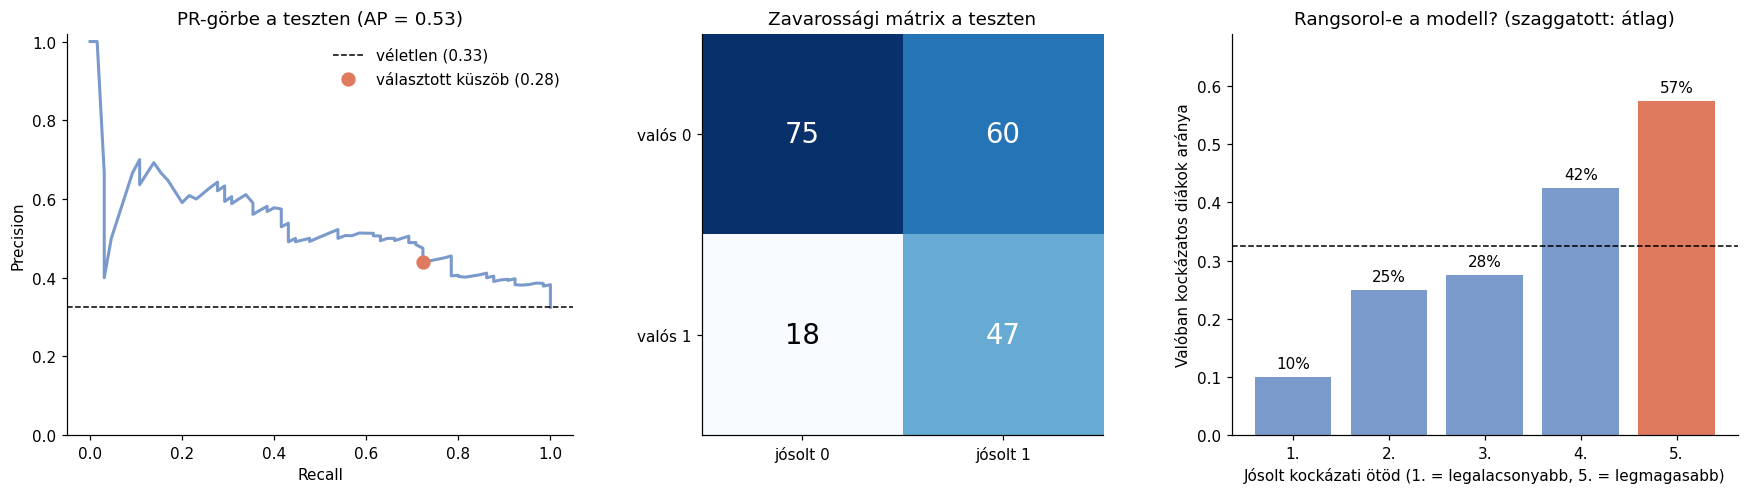

In [14]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

precision, recall, _ = precision_recall_curve(y_test, test_prob)
axes[0].plot(recall, precision, color=BLUE, lw=2)
axes[0].axhline(y_test.mean(), color="black", ls="--", lw=1, label=f"véletlen ({y_test.mean():.2f})")
axes[0].scatter([tp / (tp + fn)], [tp / max(tp + fp, 1)], color=ORANGE, s=70, zorder=3, label=f"választott küszöb ({threshold:.2f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_ylim(0, 1.02)
axes[0].set_title(f"PR-görbe a teszten (AP = {final_ap:.2f})"); axes[0].legend(frameon=False)

cm = np.array([[tn, fp], [fn, tp]])
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=18, color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], ["jósolt 0", "jósolt 1"]); axes[1].set_yticks([0, 1], ["valós 0", "valós 1"])
axes[1].set_title("Zavarossági mátrix a teszten")

quint = pd.qcut(pd.Series(test_prob).rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
actual = pd.Series(y_test.to_numpy()).groupby(quint.to_numpy()).mean()
axes[2].bar([f"{i}." for i in actual.index], actual.values, color=[BLUE] * 4 + [ORANGE])
axes[2].axhline(y_test.mean(), color="black", ls="--", lw=1)
for i, v in enumerate(actual.values):
    axes[2].text(i, v + 0.015, f"{v:.0%}", ha="center")
axes[2].set_xlabel("Jósolt kockázati ötöd (1. = legalacsonyabb, 5. = legmagasabb)")
axes[2].set_ylabel("Valóban kockázatos diákok aránya"); axes[2].set_ylim(0, max(actual.max() * 1.2, 0.5))
axes[2].set_title("Rangsorol-e a modell? (szaggatott: átlag)")
fig.tight_layout(); plt.show()

## 11. Mit tanultunk?

**A hipotézis (H1) támogatott.** Az ebéd típusa és a felkészítő kurzus megléte egyedül is a véletlen fölé emeli a jóslatot: a csak e két változós modell átlagos PR-AUC-ja 0,45 a dummy 0,32-es értékével szemben, és a különbség (+0,129 ± 0,039) nagyobb a hajtásszórásnál. A kedvezményes ebédet kapó, kurzust nem végzett diákok csoportjában 54% a kockázatos, a normál ebédet kapó, kurzust végzettekében 14,5%.

**A másik három háttérváltozó is hozzátesz** (+0,090 ± 0,035; PR-AUC 0,54), ezért az egyszerű logisztikus regresszió mind az 5 változóval a modell-létra nyertese. A döntési fa memorizál (0,40), a Random Forest és a gradient boosting (0,51) nem előzi meg a logisztikus regressziót; a hangolás sem javított a hajtásszóráson túl, ezért az egyszerűbb alapmodellt tartottuk meg.

**A teszten (egyszer, a rögzített 0,28-as küszöbbel):** PR-AUC 0,53 (95%-os intervallum: 0,43–0,67) a 0,33-es véletlen alapvonallal szemben, kiegyensúlyozott pontosság 0,64. A modell a 65 kockázatos diákból 47-et megtalál (recall 0,72), de a riasztásoknak csak 44%-a jogos (60 téves riasztás). A legkockázatosabb 20% 57,5%-a valóban kockázatos, ez az átlag 1,77-szerese, a rangsor ötödönként növekvő (10% → 57%).

**Mit jelent ez?** A háttér **valódi, de mérsékelt** jelzés: korai szűrésre (kit érdemes megkérdezni, kinek ajánlani felkészítőt) jó kiindulás, egyéni döntésre kevés. Hogy a kurzus *okozza-e* a jobb eredményt, ebből az adatból nem állítható.


## 12. Mire vigyázzunk? Amit az eredmény nem mond meg

- Az eredmény csak erre az 1 000 rekordos, egyetlen iskolai környezetből származó (valószínűleg szintetikus vagy oktatási célú) adathalmazra vonatkozik; külső validáció nélkül az általánosíthatósága nem igazolt.
- A `lunch` csak az anyagi helyzet **közelítése**, a `group` anonimizált; a változók és a pontszám közti kapcsolat korreláció, **nem ok-okozati összefüggés**.
- A modell nem alkalmas egyéni döntések (például diákok kategorizálására) önmagában: csak háttérváltozókat használ, így a tényleges tudásról keveset tud. Ha csoportokat kezelünk eltérően, méltányossági kérdések merülnek fel.
- A küszöb és a hibaköltségek feltevésen alapulnak; valós használatnál a költségeket az iskolának kell megadnia.
- Mindössze 5 diszkrét jellemző van, ezért sok diák kap azonos valószínűséget, és a teszthalmaz (200 sor) kicsi: a mutatók bizonytalansága nagy, a bootstrap-intervallum ezt tükrözi.